In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

# Data augmentation

## Baseline results

In [32]:
aug_dict = {
    "Severe dysplasia": 80,
    "Benign": 80,
}

**SVM with data augmentation**

In [33]:
m = SVC(probability=True, random_state=0)

In [34]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 81 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 82 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 81 entries


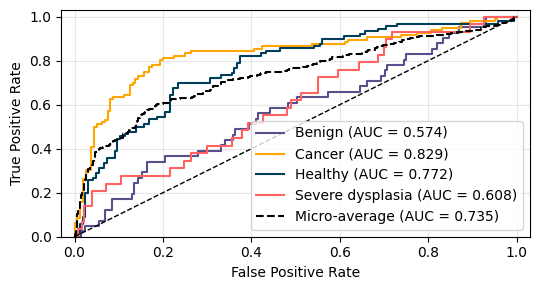

In [35]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_aug_baseline.pdf",
)

**RF with data augmentation**

In [36]:
m = RandomForestClassifier()

In [37]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 82 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 84 entries
Benign: 82 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 81 entries
Benign: 83 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 82 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 81 entries


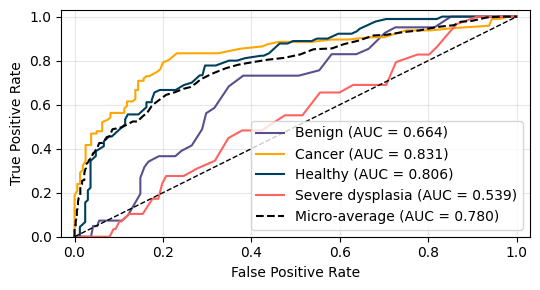

In [38]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_RF_aug_baseline.pdf",
)

**LR with data augmentation**

In [39]:
m = LogisticRegression()

In [40]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 83 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 82 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 81 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 82 entries


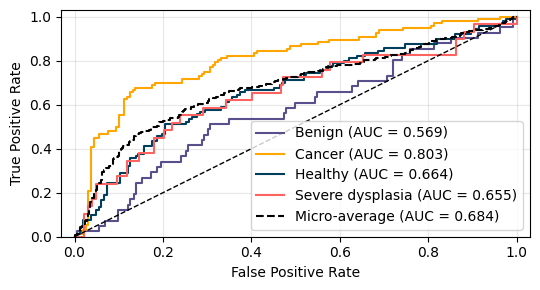

In [41]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_LR_aug_baseline.pdf",
)

## Final results

**SVM with data augmentation**

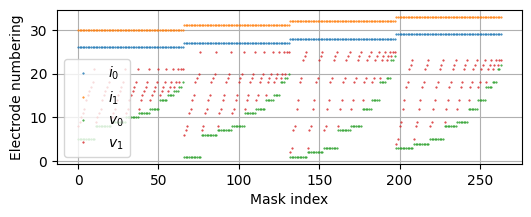

In [33]:
Msel = "Opp. medium"
Fsel = "Top 3"
m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

In [34]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        snr_db,
        prints=False,
    )
    X_train = X_train[:, Freq_sel[Fsel], :]
    X_train = X_train[:, :, mask.mask]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, Freq_sel[Fsel], :]
    X_test = X_test[:, :, mask.mask]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 71 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 71 entries
Benign: 73 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 71 entries
Benign: 71 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 72 entries
Benign: 72 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 71 entries
Benign: 71 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 72 entries


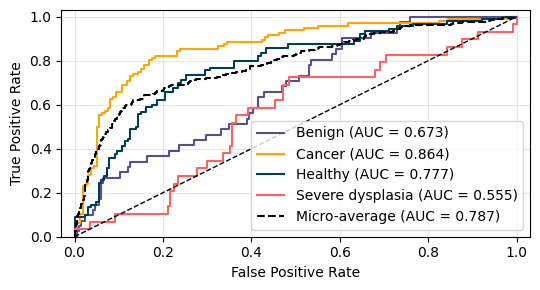

In [35]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_aug.pdf",
)

**RF with data augmentation**

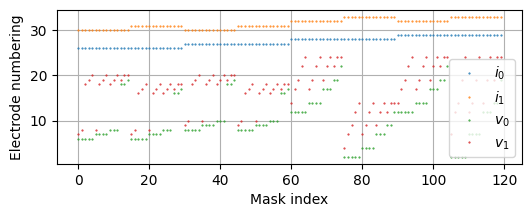

In [36]:
Msel = "Med. a+ ext."
Fsel = "Top 3"
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=1,
)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

In [37]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        snr_db,
        prints=False,
    )
    X_train = X_train[:, Freq_sel[Fsel], :]
    X_train = X_train[:, :, mask.mask]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, Freq_sel[Fsel], :]
    X_test = X_test[:, :, mask.mask]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 72 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 72 entries
Benign: 71 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 71 entries
Benign: 71 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 71 entries
Benign: 72 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 73 entries
Benign: 71 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 71 entries


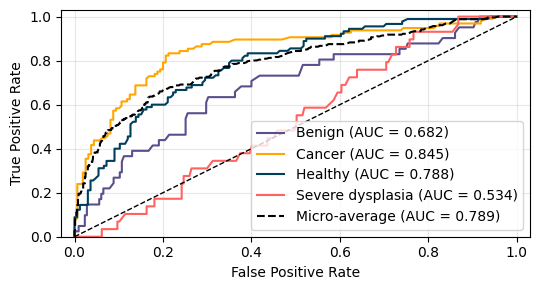

In [38]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_RF_aug.pdf"
)

**LR with data augmentation**

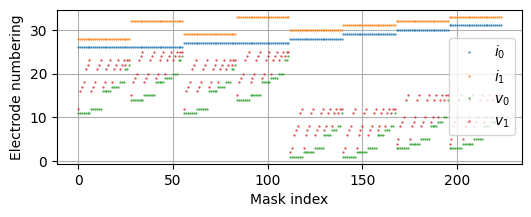

In [39]:
Msel = "Skip1 far"
Fsel = "Top 2"
m = LogisticRegression(C=1.0, max_iter=1000)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

In [40]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        snr_db,
        prints=False,
    )
    X_train = X_train[:, Freq_sel[Fsel], :]
    X_train = X_train[:, :, mask.mask]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, Freq_sel[Fsel], :]
    X_test = X_test[:, :, mask.mask]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 71 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 73 entries
Benign: 73 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 72 entries
Benign: 72 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 71 entries
Benign: 72 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 71 entries
Benign: 71 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 72 entries


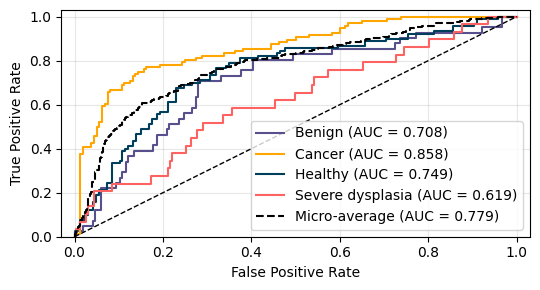

In [41]:
ResultsROCAUC(
    class_task, y_true, y_score, Y_labels, s_name=f"results/ROC_{class_task}_LR_aug.pdf"
)

___

___